# Stego_Shield: detection experiments
In this notebook, we use random and sequential embedding at few varying message SIZES_ to run the detector on both clean and stego_ pictures.

In [1]:
import sys, glob, os, csv
sys.path.append('..')    #let us import from stego_/ and analysis/
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from stego.embed import embed_message
from analysis.detector import detect
from analysis.chi_square import chi_square_test
from analysis.histogram import plot_histograms

## 1. Generate stego_ images_
We create one sequential and one random version for each cover image and message size (10%, 25%, and 50% of capacity).

In [2]:
covers_ = sorted(glob.glob('../data/cover_images/*.png'))
SIZES_ = [0.10, 0.25, 0.50]
MODES_ = ['sequential', 'random']
os.makedirs('../data/stego_images', exist_ok=True)

images_= []   # (name_, mode, size_, path)
for cover in covers_:
    name_ = os.path.basename(cover)[:-4]
    images_.append((name_, 'clean', 0, cover))
    capacity_bytes_ = np.array(Image.open(cover).convert('RGB')).size // 8
    for size_ in SIZES_:
        message = 'A' * int(size_ * capacity_bytes_ - 50)   # leave 50 bytes for the header and AES overhead
        for mode in MODES_:
            out = f'../data/stego_images/{name_}_{mode}_{int(size_*100)}.png'
            embed_message(cover, out, message, 'password123', mode)
            images_.append((name_, mode, size_, out))
print(len(covers_), 'covers,', len(images_), 'images in total')

20 covers, 140 images in total


## 2. Run the detector on clean and stego_ images_

In [3]:
results_ = []
for name_, mode, size_, path in images_:
    r = detect(path)
    results_.append({'image': name_, 'mode': mode, 'size': size_, **r})

with open('../results/detection_results.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=results_[0].keys())
    writer.writeheader(); writer.writerows(results_)

for r in results_[:7]:
    print(r)

{'image': 'a', 'mode': 'clean', 'size': 0, 'likely_hidden': False, 'confidence': 1.0, 'chi_square_p': 3.6041374549657843e-187, 'lsb_ratio': 0.4986775716145833, 'pair_diff': 1.0}
{'image': 'a', 'mode': 'sequential', 'size': 0.1, 'likely_hidden': False, 'confidence': 1.0, 'chi_square_p': 1.7062836432290362e-93, 'lsb_ratio': 0.5009256998697916, 'pair_diff': 1.0}
{'image': 'a', 'mode': 'random', 'size': 0.1, 'likely_hidden': False, 'confidence': 1.0, 'chi_square_p': 3.05963277486631e-145, 'lsb_ratio': 0.4989420572916667, 'pair_diff': 1.0}
{'image': 'a', 'mode': 'sequential', 'size': 0.25, 'likely_hidden': False, 'confidence': 1.0, 'chi_square_p': 6.620988093358988e-67, 'lsb_ratio': 0.5007069905598959, 'pair_diff': 1.0}
{'image': 'a', 'mode': 'random', 'size': 0.25, 'likely_hidden': False, 'confidence': 1.0, 'chi_square_p': 3.0589535543481835e-88, 'lsb_ratio': 0.4995168050130208, 'pair_diff': 1.0}
{'image': 'a', 'mode': 'sequential', 'size': 0.5, 'likely_hidden': False, 'confidence': 1.0, '

## 3. Accuracy table and graphs
All figures get saved to ../results/

In [4]:
def rate(mode, size_):
    rows = [r for r in results_ if r['mode'] == mode and r['size'] == size_]
    return 100 * sum(r['likely_hidden'] for r in rows) / len(rows)

print(f"Clean images_flagged(false positives): {rate('clean', 0):.0f}%")
print(f"{'size':>6} {'sequential':>11} {'random':>8}")
table = [['size', 'sequential detected %', 'random detected %']]
for size_ in SIZES_:
    s, r = rate('sequential', size_), rate('random', size_)
    print(f"{int(size_*100):>5}% {s:>10.0f}% {r:>7.0f}%")
    table.append([f'{int(size_*100)}%', s, r])
table.append(['clean (false positives)', rate('clean', 0), rate('clean', 0)])
with open('../results/detection_rates.csv', 'w', newline='') as f:
    csv.writer(f).writerows(table)

Clean images_flagged(false positives): 0%
  size  sequential   random
   10%         75%       5%
   25%         80%      10%
   50%         95%      70%


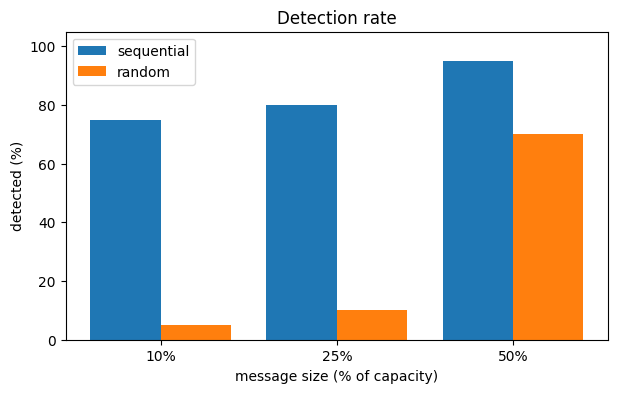

In [5]:
# Graph 1: detection rate
labels = [f'{int(s*100)}%' for s in SIZES_]
x = np.arange(len(SIZES_))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, [rate('sequential', s) for s in SIZES_], 0.4, label='sequential')
plt.bar(x + 0.2, [rate('random', s) for s in SIZES_], 0.4, label='random')
plt.xticks(x, labels); plt.xlabel('message size (% of capacity)'); plt.ylabel('detected (%)')
plt.title('Detection rate'); plt.legend(); plt.ylim(0, 105)
plt.savefig('../results/detection_rate.png', dpi=150, bbox_inches='tight'); plt.show()

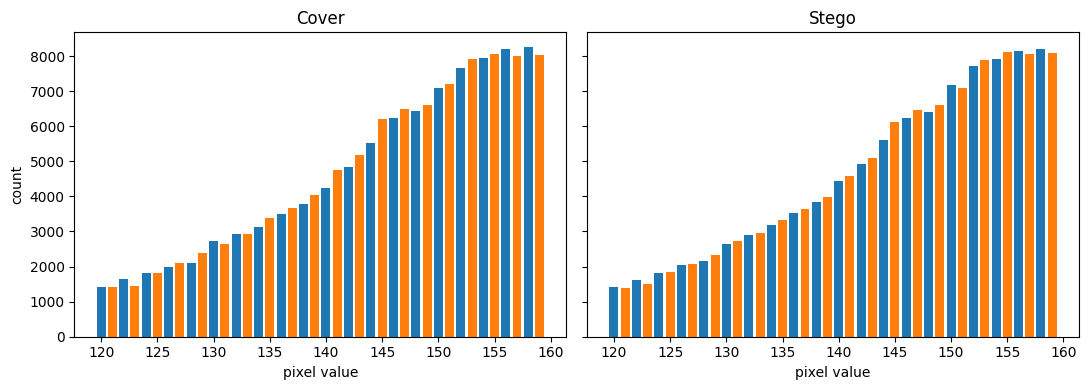

In [6]:
# Graph 2: cover vs stego_ histogram (the pairs become equal)
cover = np.array(Image.open('../data/cover_images/camera.png').convert('RGB'))
stego_ = np.array(Image.open('../data/stego_images/camera_random_50.png').convert('RGB'))
plot_histograms(cover, stego_, '../results/histogram_cover_vs_stego.png'); plt.show()

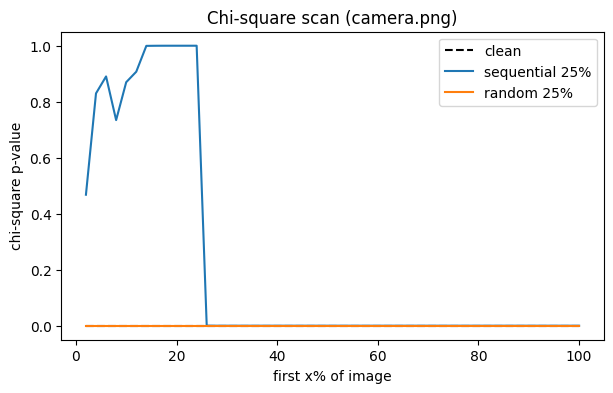

In [7]:
# Graph 3: chi-square p-value over the first x% of the image
fractions_ = np.linspace(0.02, 1, 50)
plt.figure(figsize=(7, 4))
plt.plot(fractions_ * 100, [chi_square_test(cover, f) for f in fractions_], 'k--', label='clean')
for mode in MODES_:
    img_ = np.array(Image.open(f'../data/stego_images/camera_{mode}_25.png').convert('RGB'))
    plt.plot(fractions_ * 100, [chi_square_test(img_, f) for f in fractions_], label=f'{mode} 25%')
plt.xlabel('first x% of image'); plt.ylabel('chi-square p-value'); plt.title('Chi-square scan (camera.png)')
plt.legend(); plt.savefig('../results/chi_square_scan.png', dpi=150, bbox_inches='tight'); plt.show()

## Result
- Clean images_: none were flagged.
- Sequential: simple to detect. From the beginning of the image to the finish of the message, p ≈ 1
- Random: short messages are difficult to catch. At 50%, it was mostly detected.